# 01. Exploratory Data Analysis: NYC LL84 Building Energy Benchmarking
**DTSC 691 Capstone: Building energy benchmarking anomaly detection**

Three EDA questions from the approved proposal: (1) what does the target (site EUI) look like, (2) which features drive it, and (3) how reliable is the self-reported data.
Input: `data/processed/ll84_all_classified.parquet` (created by `scripts/01_build_dataset.py`).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src import config as C
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
C.FIGS.mkdir(parents=True, exist_ok=True)
def save(name): plt.savefig(C.FIGS / f"{name}.png", dpi=150); plt.show()

df = pd.read_parquet(C.PROCESSED / "ll84_all_classified.parquet")
ready = df[df.status == "model_ready"].copy()
print(f"{len(df):,} property-years after de-duplication | {len(ready):,} model-ready | {ready.property_id.nunique():,} unique buildings")
df.groupby(["year", "status"]).size().unstack(fill_value=0)

102,484 property-years after de-duplication | 83,217 model-ready | 36,088 unique buildings


status,dq_anomaly,model_ready,out_of_scope
year,,,
2022,1343,26956,2033
2023,1792,28077,3193
2024,1864,28184,9042


## Scope and data-quality classes
Every record is classified as **model_ready**, **dq_anomaly** (implausible values, kept as its own anomaly class per the proposal) or **out_of_scope**.

,status,dq_reason,records
5,out_of_scope,missing_required_energy,12015
0,dq_anomaly,gfa_below_25k_or_invalid,3427
1,dq_anomaly,site_eui_out_of_range,1552
7,out_of_scope,type_under_50_buildings,1131
3,out_of_scope,excluded_type,727
6,out_of_scope,not_existing_building,325
4,out_of_scope,missing_property_type,70
2,dq_anomaly,year_built_invalid,20


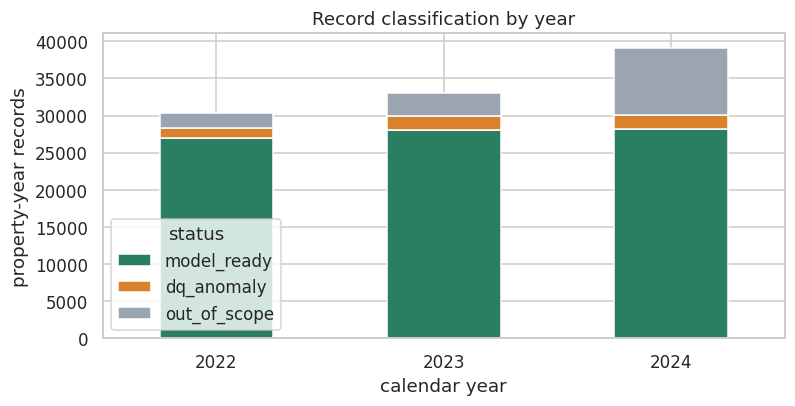

In [2]:
reasons = df[df.status != "model_ready"].groupby(["status", "dq_reason"]).size().rename("records").reset_index().sort_values("records", ascending=False)
display(reasons)
fig, ax = plt.subplots(figsize=(8, 3.6))
(df.groupby(["year", "status"]).size().unstack(fill_value=0)[["model_ready", "dq_anomaly", "out_of_scope"]]).plot.bar(stacked=True, ax=ax, color=["#2a7f62", "#d9822b", "#9aa5b1"])
ax.set_ylabel("property-year records"); ax.set_xlabel("calendar year"); ax.set_title("Record classification by year"); plt.xticks(rotation=0)
save("01_record_classification")

## 1. Target distribution: site EUI

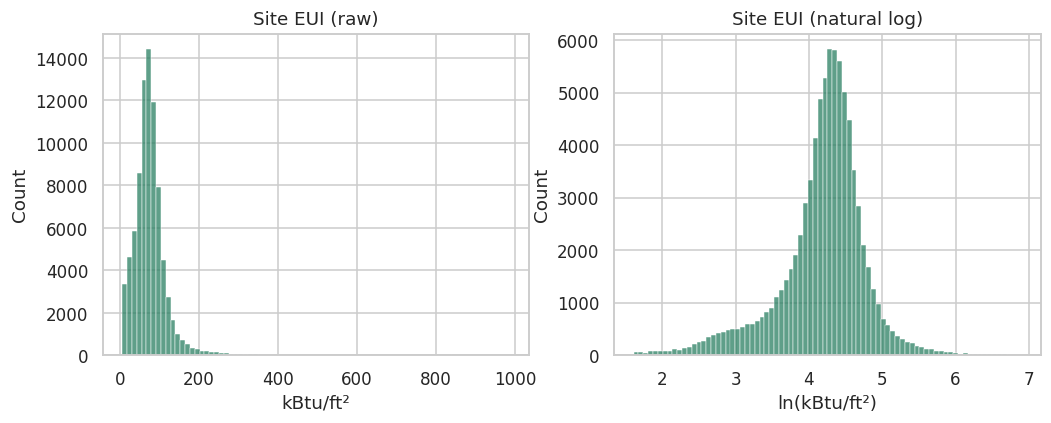

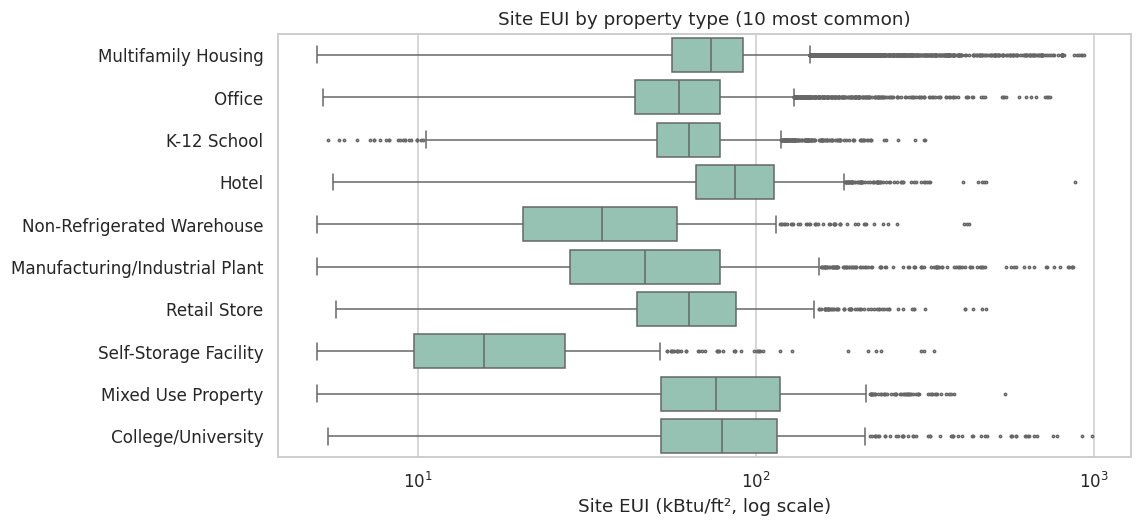

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(ready.site_eui, bins=80, ax=axes[0], color="#2a7f62"); axes[0].set_title("Site EUI (raw)"); axes[0].set_xlabel("kBtu/ft²")
sns.histplot(ready.log_site_eui, bins=80, ax=axes[1], color="#2a7f62"); axes[1].set_title("Site EUI (natural log)"); axes[1].set_xlabel("ln(kBtu/ft²)")
save("02_eui_distribution")

top = ready.prop_type.value_counts().head(10).index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=ready[ready.prop_type.isin(top)], y="prop_type", x="site_eui", order=top, ax=ax, fliersize=1.5, color="#8fc9b5")
ax.set_xscale("log"); ax.set_xlabel("Site EUI (kBtu/ft², log scale)"); ax.set_ylabel(""); ax.set_title("Site EUI by property type (10 most common)")
save("03_eui_by_type_box")

In [4]:
def q(s): return pd.Series({"n": len(s), "p1": s.quantile(.01), "p25": s.quantile(.25), "median": s.median(), "p75": s.quantile(.75), "p99": s.quantile(.99)})
summary = ready.groupby("prop_type").site_eui.apply(q).unstack()
summary["IQR"] = summary.p75 - summary.p25
summary["national_median"] = ready.groupby("prop_type").nat_median_site_eui.median()
summary["median_vs_national"] = (summary["median"] / summary.national_median).round(2)
summary.sort_values("n", ascending=False).head(15).round(1)

,n,p1,p25,median,p75,p99,IQR,national_median,median_vs_national
prop_type,,,,,,,,,
Multifamily Housing,57990.0,12.1,56.3,73.7,91.5,199.5,35.2,82.8,0.9
Office,6695.0,9.5,43.9,59.0,78.1,234.0,34.2,83.5,0.7
K-12 School,5263.0,15.5,51.0,63.3,78.0,155.3,27.0,74.5,0.8
Hotel,1884.0,17.6,66.5,86.7,113.3,262.0,46.8,86.7,1.0
Non-Refrigerated Warehouse,1159.0,5.7,20.4,35.0,58.5,190.3,38.1,35.9,1.0
Manufacturing/Industrial Plant,1010.0,6.0,28.2,47.0,78.4,639.5,50.2,NaN,NaN
Retail Store,818.0,7.9,44.4,63.4,87.0,286.5,42.6,62.5,1.0
Self-Storage Facility,769.0,5.2,9.7,15.6,27.2,120.7,17.5,23.6,0.7
Mixed Use Property,735.0,9.5,52.2,76.2,117.6,340.9,65.5,43.8,1.7


Reading the table: `median_vs_national` compares the NYC median with the EPA national median for the same property type, as a sanity check on the reference data. Large ratios flag types where the national reference is a poor peer group for NYC (dense, older, steam/gas-heated stock).

## 2. Feature drivers and relationships

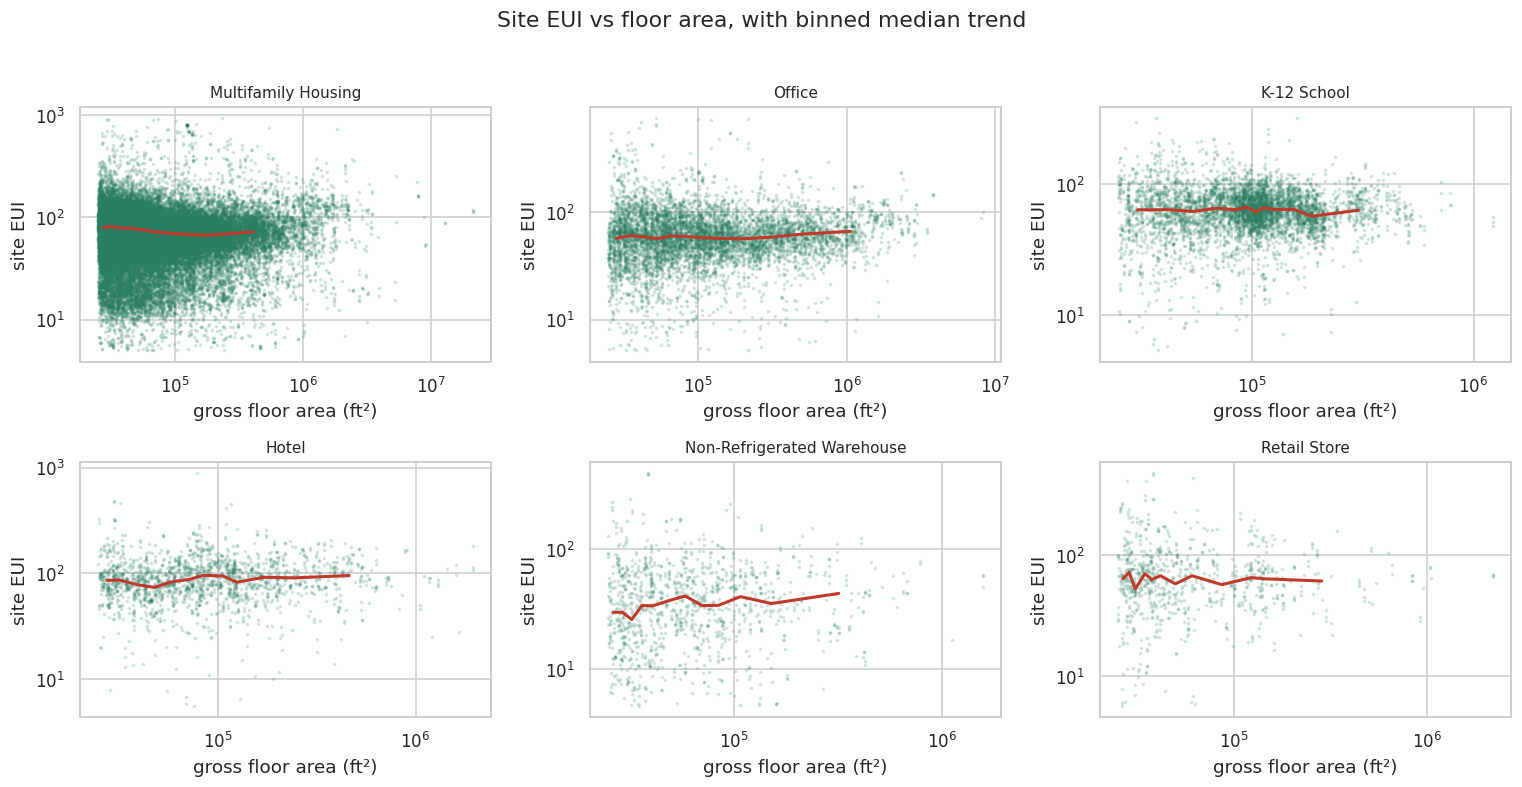

In [5]:
focus = ["Multifamily Housing", "Office", "K-12 School", "Hotel", "Non-Refrigerated Warehouse", "Retail Store"]
f = ready[ready.prop_type.isin(focus)].copy()
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=False)
for ax, t in zip(axes.ravel(), focus):
    s = f[f.prop_type == t]
    ax.scatter(s.gfa, s.site_eui, s=2, alpha=.15, color="#2a7f62")
    s = s.assign(bin=pd.qcut(s.gfa, 12, duplicates="drop"))
    b = s.groupby("bin").agg(x=("gfa", "median"), y=("site_eui", "median"))
    ax.plot(b.x, b.y, color="#c0392b", lw=2)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(t, fontsize=10); ax.set_xlabel("gross floor area (ft²)"); ax.set_ylabel("site EUI")
fig.suptitle("Site EUI vs floor area, with binned median trend", y=1.02); plt.tight_layout()
save("04_eui_vs_gfa")

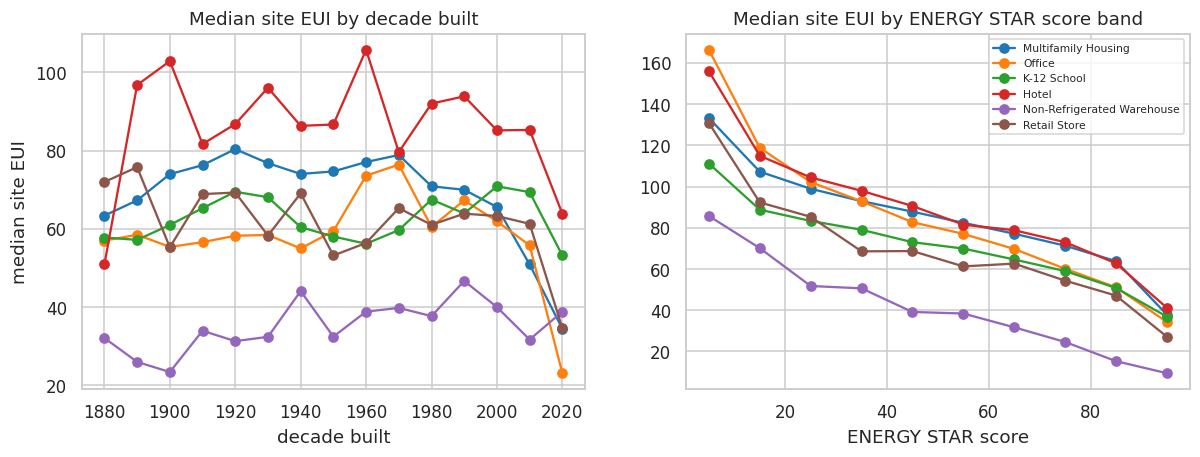

ENERGY STAR score availability by type (share of model-ready rows with a score):


prop_type
K-12 School                              0.99
Senior Living Community                  0.98
Hotel                                    0.96
Distribution Center                      0.94
Medical Office                           0.93
Multifamily Housing                      0.92
Hospital (General Medical & Surgical)    0.91
Refrigerated Warehouse                   0.91
Residence Hall/Dormitory                 0.90
Financial Office                         0.89
Name: es_score, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for t, c in zip(focus, sns.color_palette("tab10", 6)):
    s = f[(f.prop_type == t) & (f.year_built >= 1880)]
    s = s.assign(bin=pd.cut(s.year_built, np.arange(1880, 2031, 10)))
    b = s.groupby("bin", observed=True).site_eui.median()
    axes[0].plot([i.left for i in b.index], b.values, marker="o", label=t, color=c)
    s2 = f[(f.prop_type == t) & f.es_score.notna()]
    s2 = s2.assign(bin=pd.cut(s2.es_score, np.arange(0, 101, 10), include_lowest=True))
    b2 = s2.groupby("bin", observed=True).site_eui.median()
    if len(b2): axes[1].plot([i.mid for i in b2.index], b2.values, marker="o", label=t, color=c)
axes[0].set_title("Median site EUI by decade built"); axes[0].set_xlabel("decade built"); axes[0].set_ylabel("median site EUI")
axes[1].set_title("Median site EUI by ENERGY STAR score band"); axes[1].set_xlabel("ENERGY STAR score"); axes[1].legend(fontsize=7)
save("05_eui_vs_age_and_score")
print("ENERGY STAR score availability by type (share of model-ready rows with a score):")
display(ready.groupby("prop_type").es_score.apply(lambda s: s.notna().mean()).sort_values(ascending=False).head(10).round(2))

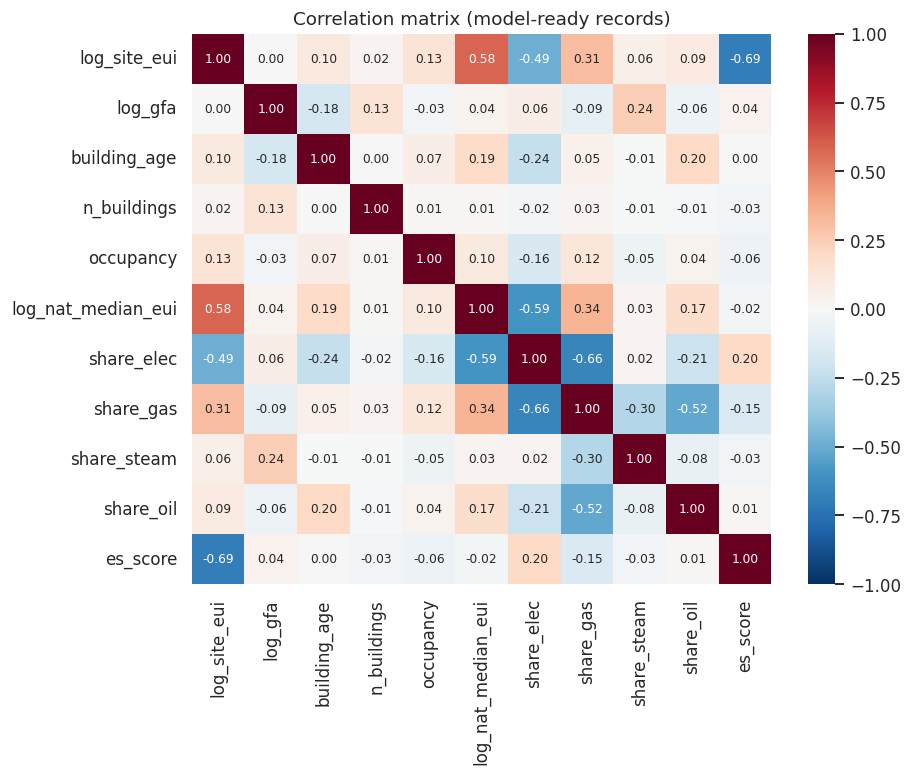

es_score             -0.69
log_nat_median_eui    0.58
share_elec           -0.49
share_gas             0.31
occupancy             0.13
building_age          0.10
share_oil             0.09
share_steam           0.06
n_buildings           0.02
log_gfa               0.00
Name: log_site_eui, dtype: float64

In [7]:
num = ["log_site_eui", "log_gfa", "building_age", "n_buildings", "occupancy", "log_nat_median_eui", "share_elec", "share_gas", "share_steam", "share_oil", "es_score"]
corr = ready[num].corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8}); ax.set_title("Correlation matrix (model-ready records)")
save("06_correlation")
corr.log_site_eui.drop("log_site_eui").sort_values(key=abs, ascending=False).round(2)

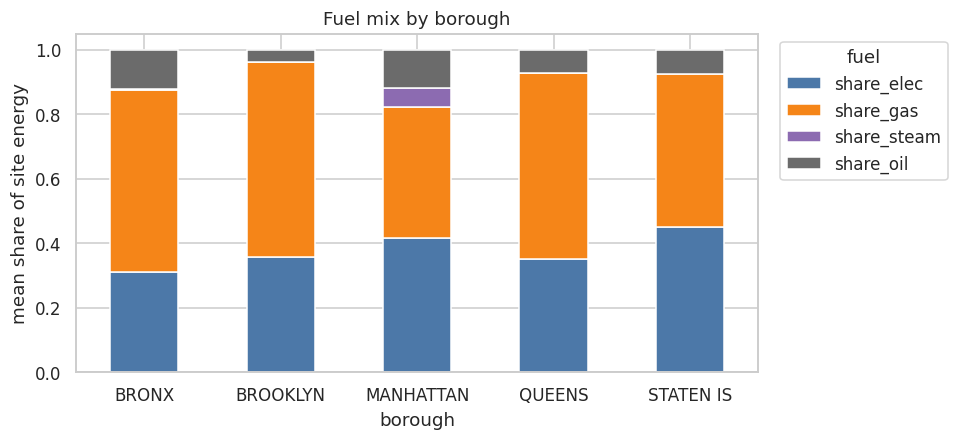

In [8]:
fm = ready.dropna(subset=["borough"]).groupby("borough")[["share_elec", "share_gas", "share_steam", "share_oil"]].mean()
fm.plot.bar(stacked=True, figsize=(8, 4), color=["#4c78a8", "#f58518", "#8c6bb1", "#6b6b6b"]); plt.xticks(rotation=0)
plt.ylabel("mean share of site energy"); plt.title("Fuel mix by borough"); plt.legend(title="fuel", bbox_to_anchor=(1.02, 1), loc="upper left")
save("07_fuel_mix_by_borough")
fig = px.scatter(ready[ready.prop_type.isin(focus)].sample(8000, random_state=42), x="gfa", y="site_eui", color="prop_type", log_x=True, log_y=True, opacity=.4,
                 hover_data=["property_id", "year_built", "borough"], title="Site EUI vs floor area (interactive, 8k sample)")
fig.write_html(C.FIGS / "interactive_eui_vs_gfa.html"); fig.show()

## 3. Reliability and missingness

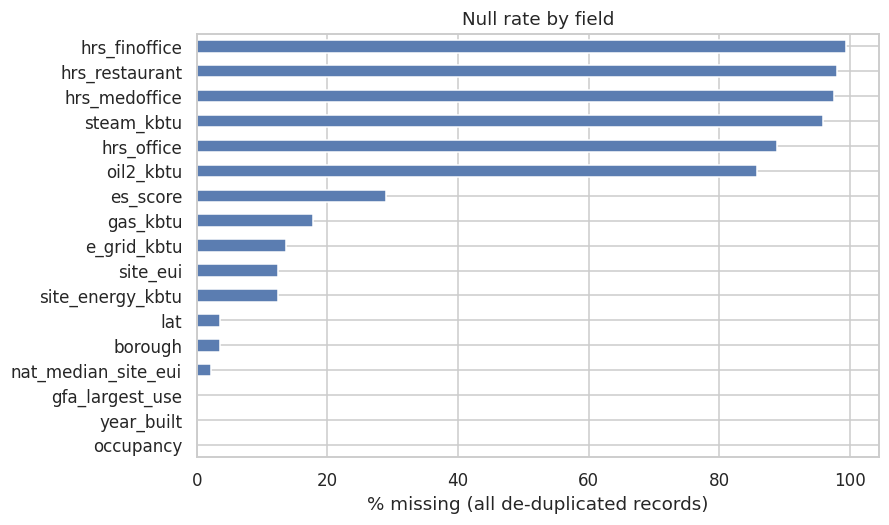

occupancy               0.0
year_built              0.0
gfa_largest_use         0.1
nat_median_site_eui     2.2
borough                 3.6
lat                     3.6
site_energy_kbtu       12.5
site_eui               12.5
e_grid_kbtu            13.7
gas_kbtu               17.7
es_score               29.0
oil2_kbtu              85.7
hrs_office             88.9
steam_kbtu             95.9
hrs_medoffice          97.6
hrs_restaurant         98.0
hrs_finoffice          99.5
dtype: float64

In [9]:
check = ["site_eui", "site_energy_kbtu", "es_score", "nat_median_site_eui", "gfa_largest_use", "year_built", "occupancy",
         "hrs_office", "hrs_medoffice", "hrs_finoffice", "hrs_restaurant", "e_grid_kbtu", "gas_kbtu", "steam_kbtu", "oil2_kbtu", "borough", "lat"]
nulls = (df[check].isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 5)); nulls.plot.barh(ax=ax, color="#5b7db1"); ax.set_xlabel("% missing (all de-duplicated records)"); ax.set_title("Null rate by field")
save("08_null_rates")
nulls.round(1)

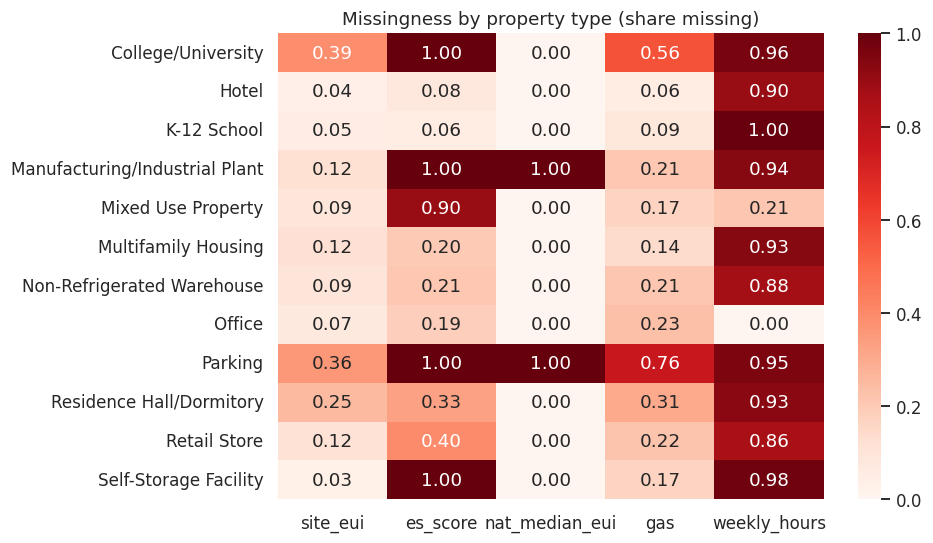

,site_eui_missing,es_score_missing,default_values,estimated_energy
year,,,,
2022,0.052,0.217,0.136,0.115
2023,0.082,0.254,0.142,0.546
2024,0.218,0.377,0.244,0.500


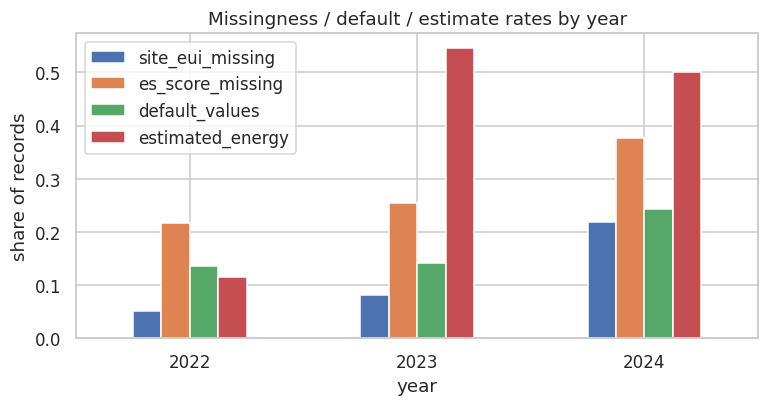

In [10]:
df["has_hours"] = df[["hrs_office", "hrs_medoffice", "hrs_finoffice", "hrs_restaurant"]].notna().any(axis=1)
top12 = df.prop_type.value_counts().head(12).index
m = df[df.prop_type.isin(top12)].groupby("prop_type")[["site_eui", "es_score", "nat_median_site_eui", "occupancy", "e_grid_kbtu", "gas_kbtu", "has_hours"]].apply(lambda g: g.isna().mean() if False else pd.Series({
    "site_eui": g.site_eui.isna().mean(), "es_score": g.es_score.isna().mean(), "nat_median_eui": g.nat_median_site_eui.isna().mean(),
    "gas": g.gas_kbtu.isna().mean(), "weekly_hours": 1 - g.has_hours.mean()}))
fig, ax = plt.subplots(figsize=(8, 5.5)); sns.heatmap(m, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax); ax.set_ylabel(""); ax.set_title("Missingness by property type (share missing)")
save("09_missingness_by_type")
y = df.groupby("year").agg(site_eui_missing=("site_eui", lambda s: s.isna().mean()), es_score_missing=("es_score", lambda s: s.isna().mean()), default_values=("default_values", "mean"), estimated_energy=("estimated_energy", "mean")).round(3)
display(y)
y.plot.bar(figsize=(8, 3.6), rot=0); plt.title("Missingness / default / estimate rates by year"); plt.ylabel("share of records")
save("10_missingness_by_year")

**Operating hours.** Weekly operating hours exist only for four use types (Office, Medical Office, Financial Office, Restaurant), so for the full model-ready set the field is about 85% missing. The proposal's rule (drop features missing more than 40%) therefore removes it from the global model; it can still be used in an office-only sensitivity model.

Duplicate Property ID x year rows removed during cleaning: see reports/dataset_build_log.json


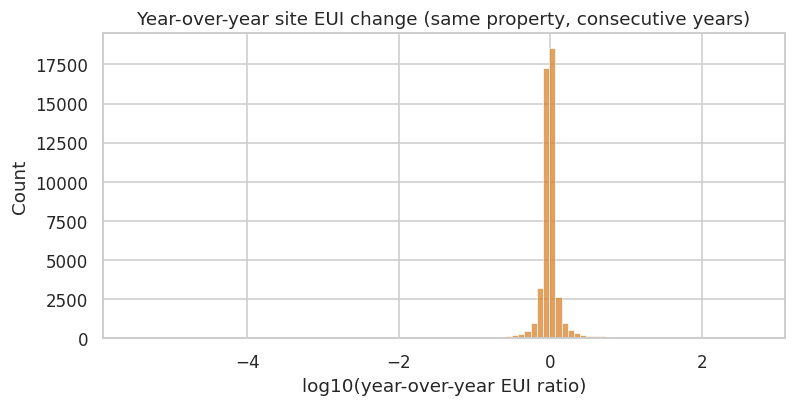

YoY ratio > 3x or < 1/3: 1,365 of 47,079 (2.90%)  <- candidate entry errors for the proxy-label set


,records
dq_reason,
gfa_below_25k_or_invalid,3427
site_eui_out_of_range,1552
year_built_invalid,20


prop_type
Multifamily Housing    1919
Other - Recreation      604
Office                  245
Library                 229
K-12 School             186
College/University      163
Pre-school/Daycare      160
Fire Station            148
Name: dq records, dtype: int64

In [11]:
print("Duplicate Property ID x year rows removed during cleaning: see reports/dataset_build_log.json")
yoy = ready.eui_yoy_ratio.dropna()
fig, ax = plt.subplots(figsize=(8, 3.6)); sns.histplot(np.log10(yoy), bins=100, ax=ax, color="#d9822b")
ax.set_xlabel("log10(year-over-year EUI ratio)"); ax.set_title("Year-over-year site EUI change (same property, consecutive years)")
save("11_yoy_ratio")
print(f"YoY ratio > 3x or < 1/3: {((yoy > 3) | (yoy < 1/3)).sum():,} of {len(yoy):,} ({((yoy > 3) | (yoy < 1/3)).mean():.2%})  <- candidate entry errors for the proxy-label set")
dq = df[df.status == "dq_anomaly"]
display(dq.groupby("dq_reason").size().rename("records").to_frame())
dq.groupby("prop_type").size().sort_values(ascending=False).head(8).rename("dq records")

## Key findings
Filled in after execution: see the next cell, which prints the numbers used in the write-up.

In [12]:
print(f"Records after de-dup: {len(df):,}; model-ready: {len(ready):,} ({len(ready)/len(df):.0%}); dq anomalies: {(df.status=='dq_anomaly').sum():,}")
print(f"Multifamily share of model-ready records: {(ready.prop_type=='Multifamily Housing').mean():.0%}")
print(f"Site EUI missing: " + ", ".join(f"{k}: {v:.1%}" for k, v in df.groupby('year').site_eui.apply(lambda s: s.isna().mean()).items()))
print(f"Default-value flag rate: {df.default_values.mean():.1%}; estimated-energy flag rate: {df.estimated_energy.mean():.1%}")
print(f"Occupancy exactly 100%: {(df.occupancy==100).mean():.1%}")
print(f"ENERGY STAR score available: {ready.es_score.notna().mean():.1%} of model-ready records")

Records after de-dup: 102,484; model-ready: 83,217 (81%); dq anomalies: 4,999
Multifamily share of model-ready records: 70%
Site EUI missing: 2022: 5.2%, 2023: 8.2%, 2024: 21.8%
Default-value flag rate: 17.9%; estimated-energy flag rate: 39.4%
Occupancy exactly 100%: 85.6%
ENERGY STAR score available: 85.2% of model-ready records
